In [ ]:
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [ ]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
import nibabel as nib
from pathlib import Path
import joblib
import matplotlib.pyplot as plt

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"Detected GPU: {gpus}")
    except RuntimeError as e:
        print(e)

TARGET_SHAPE_2D = (128, 128)
BATCH_SIZE = 4
FINE_TUNING_LR = 1e-5
EPOCHS_FT = 15

BASE_DIR = Path("/content/drive/MyDrive/Colab Notebooks")
MANIFEST_CSV = BASE_DIR / "processed/manifest_preproc.csv"
LABELS_CSV = BASE_DIR / "labels_TTF1_CK7.csv"
RADIOMICS_DIR = BASE_DIR / "radiomics_ct"

SAVED_MODEL_PATH = BASE_DIR / "cnn_2d/model_2d_efficientnet_radiomics_finetuned.keras"
SAVED_SCALER_PATH = BASE_DIR / "cnn_2d/radiomics_scaler.joblib"

NEW_MODEL_PATH = BASE_DIR / "model_2d_efficientnet_radiomics_v3.keras"
print("TensorFlow version:", tf.__version__)

Detected GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
TensorFlow version: 2.19.0


In [ ]:
def load_ct_volume(ct_path):
    try:
        img = nib.load(ct_path)
        vol = img.get_fdata().astype(np.float32)
        vol = np.nan_to_num(vol)
        if len(vol.shape) == 3:
            vol = np.expand_dims(vol, axis=-1)
        return vol
    except Exception as e:
        print(f"Err loading {ct_path}: {e}")
        return None

def is_slice_informative(slice_2d, threshold=0.01, min_pixels=500):
    return np.sum(slice_2d > threshold) > min_pixels

def load_radiomics_features(path):
    feats = {}
    if not os.path.exists(path): return None
    with open(path, "r") as f:
        for line in f:
            line = line.strip()
            if not line or ":" not in line: continue
            k, v = line.split(":", 1)
            try:
                if k.startswith("original_"):
                    feats[k.strip()] = float(v.strip().replace("np.float64(", "").replace(")", ""))
            except: continue
    return feats

def slice_generator(ct_paths, X_radio, y_labels):
    num_patients = len(ct_paths)
    for i in range(num_patients):
        path = ct_paths[i]
        vol_3d = load_ct_volume(path)
        if vol_3d is None: continue

        radio_feats = X_radio[i]
        lbl_ttf1 = float(y_labels[i][0])
        lbl_ck7 = float(y_labels[i][1])

        depth = vol_3d.shape[2]
        for z in range(depth):
            slice_img = vol_3d[:, :, z, :]
            slice_resized = tf.image.resize(slice_img, TARGET_SHAPE_2D).numpy()

            if is_slice_informative(slice_resized[:, :, 0]):
                yield (slice_resized, radio_feats), {"TTF1": lbl_ttf1, "CK7": lbl_ck7}

def make_2d_dataset(ct_paths, X_radio, y, batch_size=32, shuffle=False):
    output_signature = (
        (tf.TensorSpec(shape=(128, 128, 1), dtype=tf.float32),
         tf.TensorSpec(shape=(X_radio.shape[1],), dtype=tf.float32)),
        {"TTF1": tf.TensorSpec(shape=(), dtype=tf.float32),
         "CK7": tf.TensorSpec(shape=(), dtype=tf.float32)}
    )
    ds = tf.data.Dataset.from_generator(
        lambda: slice_generator(ct_paths, X_radio, y),
        output_signature=output_signature
    )
    if shuffle:
        ds = ds.shuffle(buffer_size=2000, reshuffle_each_iteration=True)

    def expand_labels(inputs, targets):
        return inputs, {"TTF1": tf.expand_dims(targets["TTF1"], -1), "CK7": tf.expand_dims(targets["CK7"], -1)}

    ds = ds.map(expand_labels, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

In [ ]:

df_labels = pd.read_csv(LABELS_CSV)
df_manifest = pd.read_csv(MANIFEST_CSV)
df_manifest.columns = [c.strip() for c in df_manifest.columns]

df_labels['Code'] = df_labels['Code'].astype(str).str.extract(r'(\d+)')[0]
df_manifest['Code'] = df_manifest['Code'].astype(str).str.extract(r'(\d+)')[0]

df_clean = df_labels.dropna(subset=['TTF1', 'CK7']).copy()
data_index = df_clean.merge(df_manifest, on='Code', how='inner')

def get_best_path(row):
    if 'ct_cropped_nifti_path' in row and pd.notna(row['ct_cropped_nifti_path']):
        return row['ct_cropped_nifti_path']
    elif 'ct_nifti_path' in row and pd.notna(row['ct_nifti_path']):
        return row['ct_nifti_path']
    return None

data_index['ct_path'] = data_index.apply(get_best_path, axis=1)
data_index['radiomics_path'] = data_index['Code'].apply(lambda x: str(RADIOMICS_DIR / f"{x}_radiomics.txt"))
data_index = data_index[data_index.apply(lambda x: os.path.exists(str(x['ct_path'])) and os.path.exists(str(x['radiomics_path'])), axis=1)].reset_index(drop=True)

all_radiomics = []
valid_indices = []
for idx, row in data_index.iterrows():
    feats = load_radiomics_features(row['radiomics_path'])
    if feats:
        all_radiomics.append(list(feats.values()))
        valid_indices.append(idx)

data_index = data_index.iloc[valid_indices].reset_index(drop=True)
X_radio_raw = np.array(all_radiomics)

val_ids_list = ['13111', '3111', '19111', '56111', '2011', '50011', '65111', '24111']
test_ids_list = ['25111', '45111', '42111', '89011', '33111', '36111', '55011', '80111', '48011']

val_df = data_index[data_index['Code'].isin(val_ids_list)].copy()
test_df = data_index[data_index['Code'].isin(test_ids_list)].copy()
train_df = data_index[~data_index['Code'].isin(val_ids_list + test_ids_list)].copy()

print(f"Dataset:")
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

print(f"Loading scaler: {SAVED_SCALER_PATH}")
scaler = joblib.load(SAVED_SCALER_PATH)
X_radio_scaled = scaler.transform(X_radio_raw)

def prepare_arrays(df):
    indices = df.index.tolist()
    paths = df['ct_path'].tolist()
    radio = X_radio_scaled[indices]
    labels = df[['TTF1', 'CK7']].values
    return paths, radio, labels

train_paths, train_radio, train_labels = prepare_arrays(train_df)
val_paths, val_radio, val_labels = prepare_arrays(val_df)
test_paths, test_radio, test_labels = prepare_arrays(test_df)

train_ds = make_2d_dataset(train_paths, train_radio, train_labels, BATCH_SIZE, shuffle=True)
val_ds = make_2d_dataset(val_paths, val_radio, val_labels, BATCH_SIZE, shuffle=False)

Dataset:
Train: 70 | Val: 8 | Test: 9
Loading scaler: /content/drive/MyDrive/Colab Notebooks/cnn_2d/radiomics_scaler.joblib


In [ ]:
def plot_history(history, title="Training History"):
    metrics = history.history
    epochs_range = range(1, len(metrics['loss']) + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, metrics['loss'], label='Train Loss')
    plt.plot(epochs_range, metrics['val_loss'], label='Val Loss')
    plt.title(f'{title} - Total Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, metrics.get('TTF1_acc', []), label='Train TTF1 Acc')
    plt.plot(epochs_range, metrics.get('val_TTF1_acc', []), label='Val TTF1 Acc', linestyle='--')
    plt.plot(epochs_range, metrics.get('CK7_acc', []), label='Train CK7 Acc')
    plt.plot(epochs_range, metrics.get('val_CK7_acc', []), label='Val CK7 Acc', linestyle='--')
    plt.title(f'{title} - Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

def run_training_round(start_model_path, train_ds, val_ds, epochs, learning_rate, save_path, patience=6):

    print(f"\nLoading base model from: {start_model_path}")
    model = tf.keras.models.load_model(start_model_path)

    for layer in model.layers:
        if "efficientnet" in layer.name or isinstance(layer, tf.keras.Model):
            layer.trainable = True
            print("Backbone Unfrozen")

    if isinstance(learning_rate, tf.keras.optimizers.schedules.LearningRateSchedule):
        print(f"Training with SCHEDULER (CosineDecay)")
        use_scheduler = True
    else:
        print(f"Training with FIXED LR: {learning_rate} (+ ReduceLROnPlateau)")
        use_scheduler = False

    print(f"Best model will be saved to: {save_path}")

    model.compile(
        optimizer=optimizers.Adam(learning_rate=learning_rate),
        loss={"TTF1": "binary_crossentropy", "CK7": "binary_crossentropy"},
        metrics={
            "TTF1": [tf.keras.metrics.BinaryAccuracy(name="acc"), tf.keras.metrics.AUC(name="auc")],
            "CK7": [tf.keras.metrics.BinaryAccuracy(name="acc"), tf.keras.metrics.AUC(name="auc")]
        }
    )

    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(save_path, monitor='val_loss', save_best_only=True, verbose=1)
    ]

    if not use_scheduler:
        callbacks.append(tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, verbose=1))

    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks)

    plot_history(history, title=f"History: {Path(save_path).name}")

    return model, history


Loading base model from: /content/drive/MyDrive/Colab Notebooks/cnn_2d/model_2d_efficientnet_radiomics_finetuned.keras
Backbone Unfrozen
Backbone Unfrozen
Training with FIXED LR: 1e-05 (+ ReduceLROnPlateau)
Best model will be saved to: /content/drive/MyDrive/Colab Notebooks/cnn_2d/model_2d_efficientnet_v3_FIXED_LR.keras
Epoch 1/15
    990/Unknown 115s 56ms/step - CK7_acc: 0.6674 - CK7_auc: 0.7403 - CK7_loss: 0.6517 - TTF1_acc: 0.7604 - TTF1_auc: 0.7972 - TTF1_loss: 0.5166 - loss: 2.2476

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_loss improved from inf to 2.65308, saving model to /content/drive/MyDrive/Colab Notebooks/cnn_2d/model_2d_efficientnet_v3_FIXED_LR.keras
990/990 ━━━━━━━━━━━━━━━━━━━━ 127s 68ms/step - CK7_acc: 0.6674 - CK7_auc: 0.7403 - CK7_loss: 0.6517 - TTF1_acc: 0.7604 - TTF1_auc: 0.7972 - TTF1_loss: 0.5166 - loss: 2.2476 - val_CK7_acc: 0.5636 - val_CK7_auc: 0.5908 - val_CK7_loss: 0.8023 - val_TTF1_acc: 0.6182 - val_TTF1_auc: 0.5308 - val_TTF1_loss: 0.7677 - val_loss: 2.6531 - learning_rate: 1.0000e-05
Epoch 2/15
989/990 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - CK7_acc: 0.6799 - CK7_auc: 0.7480 - CK7_loss: 0.6341 - TTF1_acc: 0.7648 - TTF1_auc: 0.8064 - TTF1_loss: 0.5012 - loss: 2.2009
Epoch 2: val_loss improved from 2.65308 to 2.63749, saving model to /content/drive/MyDrive/Colab Notebooks/cnn_2d/model_2d_efficientnet_v3_FIXED_LR.keras
990/990 ━━━━━━━━━━━━━━━━━━━━ 42s 36ms/step - CK7_acc: 0.6799 - CK7_auc: 0.7480 - CK7_loss: 0.6341 - TTF1_acc: 0.7648 - TTF1_auc: 0.8064 - TTF1_loss: 0.5012 - 

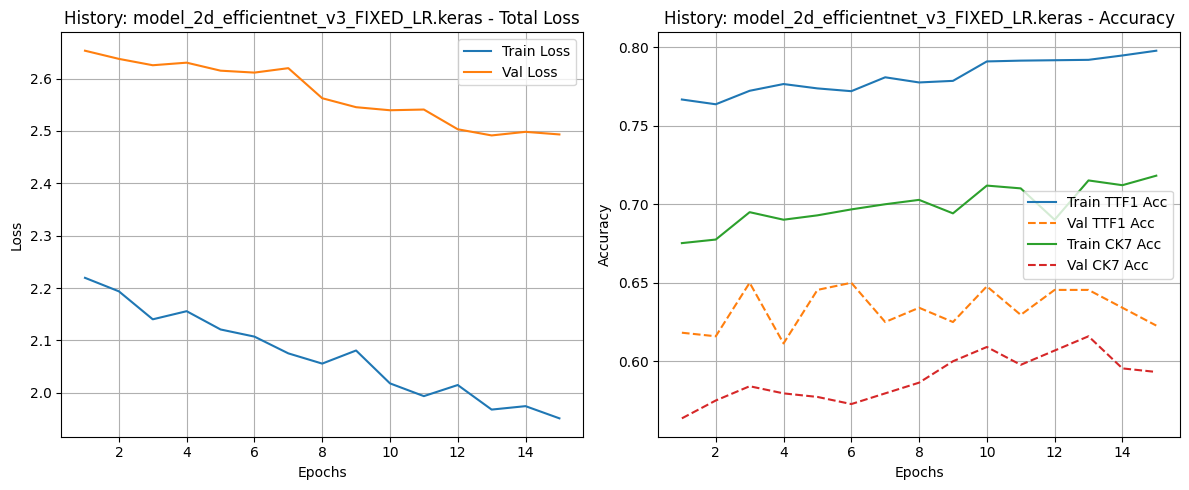

In [ ]:
MODEL_FIXED_PATH = str(BASE_DIR / "cnn_2d/model_2d_efficientnet_v3_FIXED_LR.keras")

model_fixed, hist_fixed = run_training_round(
    start_model_path=SAVED_MODEL_PATH,
    train_ds=train_ds,
    val_ds=val_ds,
    epochs=15,
    learning_rate=1e-5,
    save_path=MODEL_FIXED_PATH
)

In [ ]:
def predict_patient_aggregated(model, ct_path, radio_feats):
    vol_3d = load_ct_volume(ct_path)
    if vol_3d is None: return 0.5, 0.5

    slices = []
    depth = vol_3d.shape[2]
    for z in range(depth):
        slice_img = vol_3d[:, :, z, :]
        slice_resized = tf.image.resize(slice_img, TARGET_SHAPE_2D).numpy()

        if is_slice_informative(slice_resized[:, :, 0]):
            slices.append(slice_resized)

    if len(slices) == 0: return 0.5, 0.5

    slices_array = np.array(slices)
    radio_array = np.repeat([radio_feats], len(slices), axis=0)

    preds = model.predict([slices_array, radio_array], verbose=0)

    return np.mean(preds['TTF1']), np.mean(preds['CK7'])

def evaluate_model_performance(model, test_paths, test_radio, test_labels, model_name="Model"):
    print(f"\n Starting Evaluation for: {model_name}...")

    y_true_ttf1, y_prob_ttf1 = [], []
    y_true_ck7, y_prob_ck7 = [], []

    print(f"   Processing {len(test_paths)} patients...")

    for i in range(len(test_paths)):
        t_ttf1 = test_labels[i][0]
        t_ck7 = test_labels[i][1]

        p_ttf1, p_ck7 = predict_patient_aggregated(model, test_paths[i], test_radio[i])

        y_true_ttf1.append(t_ttf1)
        y_prob_ttf1.append(p_ttf1)
        y_true_ck7.append(t_ck7)
        y_prob_ck7.append(p_ck7)

    results = {
        "TTF1": (np.array(y_true_ttf1), np.array(y_prob_ttf1)),
        "CK7":  (np.array(y_true_ck7), np.array(y_prob_ck7))
    }

    for target_name, (y_true, y_prob) in results.items():
        fig, axes = plt.subplots(1, 2, figsize=(16, 6))
        fig.suptitle(f'Performance {model_name} - Target: {target_name}', fontsize=16)

        y_pred_05 = (y_prob >= 0.5).astype(int)
        cm = confusion_matrix(y_true, y_pred_05)

        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
                    xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
        axes[0].set_title('Confusion Matrix (Threshold 0.5)')
        axes[0].set_xlabel('Prediction')
        axes[0].set_ylabel('Actual')

        thresholds = np.arange(0.1, 1.0, 0.05)
        acc_scores, f1_scores, rec_scores, prec_scores = [], [], [], []

        for t in thresholds:
            y_pred_t = (y_prob >= t).astype(int)
            acc_scores.append(accuracy_score(y_true, y_pred_t))
            f1_scores.append(f1_score(y_true, y_pred_t, zero_division=0))
            rec_scores.append(recall_score(y_true, y_pred_t, zero_division=0))
            prec_scores.append(precision_score(y_true, y_pred_t, zero_division=0))

        axes[1].plot(thresholds, acc_scores, label='Accuracy', linestyle='-')
        axes[1].plot(thresholds, f1_scores, label='F1-Score', linewidth=3)
        axes[1].plot(thresholds, rec_scores, label='Recall', linestyle='--')
        axes[1].plot(thresholds, prec_scores, label='Precision', linestyle=':')

        axes[1].set_title('Metrics vs Threshold')
        axes[1].set_xlabel('Decision Threshold')
        axes[1].set_ylabel('Score')
        axes[1].set_ylim(0, 1.05)
        axes[1].grid(True, alpha=0.3)
        axes[1].legend()

        plt.tight_layout()
        plt.show()

        print(f"[{target_name}] Acc (0.5): {accuracy_score(y_true, y_pred_05):.4f} | F1 (0.5): {f1_score(y_true, y_pred_05):.4f}")

In [ ]:
def predict_patient_aggregated(model, ct_path, radio_feats):
    vol_3d = load_ct_volume(ct_path)
    if vol_3d is None: return 0.5, 0.5

    slices = []
    depth = vol_3d.shape[2]
    for z in range(depth):
        slice_img = vol_3d[:, :, z, :]
        slice_resized = tf.image.resize(slice_img, TARGET_SHAPE_2D).numpy()

        if is_slice_informative(slice_resized[:, :, 0]):
            slices.append(slice_resized)

    if len(slices) == 0: return 0.5, 0.5

    slices_array = np.array(slices)
    radio_array = np.repeat([radio_feats], len(slices), axis=0)

    preds = model.predict([slices_array, radio_array], verbose=0)

    return np.mean(preds['TTF1']), np.mean(preds['CK7'])

def evaluate_model_performance(model, test_paths, test_radio, test_labels, model_name="Model", threshold_ttf1=0.5, threshold_ck7=0.5):
    print(f"\n Starting Evaluation for: {model_name}...")
    print(f" Thresholds: TTF1={threshold_ttf1}, CK7={threshold_ck7}")

    y_true_ttf1, y_prob_ttf1 = [], []
    y_true_ck7, y_prob_ck7 = [], []

    print(f"   Processing {len(test_paths)} patients...")

    for i in range(len(test_paths)):
        t_ttf1 = test_labels[i][0]
        t_ck7 = test_labels[i][1]

        p_ttf1, p_ck7 = predict_patient_aggregated(model, test_paths[i], test_radio[i])

        y_true_ttf1.append(t_ttf1)
        y_prob_ttf1.append(p_ttf1)
        y_true_ck7.append(t_ck7)
        y_prob_ck7.append(p_ck7)

    results = {
        "TTF1": (np.array(y_true_ttf1), np.array(y_prob_ttf1), threshold_ttf1),
        "CK7":  (np.array(y_true_ck7), np.array(y_prob_ck7), threshold_ck7)
    }

    for target_name, (y_true, y_prob, thr) in results.items():
        fig, axes = plt.subplots(1, 2, figsize=(16, 6))
        fig.suptitle(f'Performance {model_name} - Target: {target_name}', fontsize=16)

        y_pred = (y_prob >= thr).astype(int)
        cm = confusion_matrix(y_true, y_pred)

        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
                    xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
        axes[0].set_title(f'Confusion Matrix (Threshold {thr})')
        axes[0].set_xlabel('Prediction')
        axes[0].set_ylabel('Actual')

        thresholds = np.arange(0.1, 1.0, 0.05)
        acc_scores, f1_scores, rec_scores, prec_scores = [], [], [], []

        for t in thresholds:
            y_pred_t = (y_prob >= t).astype(int)
            acc_scores.append(accuracy_score(y_true, y_pred_t))
            f1_scores.append(f1_score(y_true, y_pred_t, zero_division=0))
            rec_scores.append(recall_score(y_true, y_pred_t, zero_division=0))
            prec_scores.append(precision_score(y_true, y_pred_t, zero_division=0))

        axes[1].plot(thresholds, acc_scores, label='Accuracy', linestyle='-')
        axes[1].plot(thresholds, f1_scores, label='F1-Score', linewidth=3)
        axes[1].plot(thresholds, rec_scores, label='Recall', linestyle='--')
        axes[1].plot(thresholds, prec_scores, label='Precision', linestyle=':')

        axes[1].axvline(x=thr, color='black', linestyle='--', alpha=0.5, label=f'Chosen Thr ({thr})')

        axes[1].set_title('Metrics vs Threshold')
        axes[1].set_xlabel('Decision Threshold')
        axes[1].set_ylabel('Score')
        axes[1].set_ylim(0, 1.05)
        axes[1].grid(True, alpha=0.3)
        axes[1].legend()

        plt.tight_layout()
        plt.show()

        print(f"[{target_name} @ {thr}] Acc: {accuracy_score(y_true, y_pred):.4f} | F1: {f1_score(y_true, y_pred):.4f} | Recall: {recall_score(y_true, y_pred):.4f} | Prec: {precision_score(y_true, y_pred, zero_division=0):.4f}")



 Starting Evaluation for: Fixed LR Model...
 Thresholds: TTF1=0.65, CK7=0.7
   Processing 9 patients...


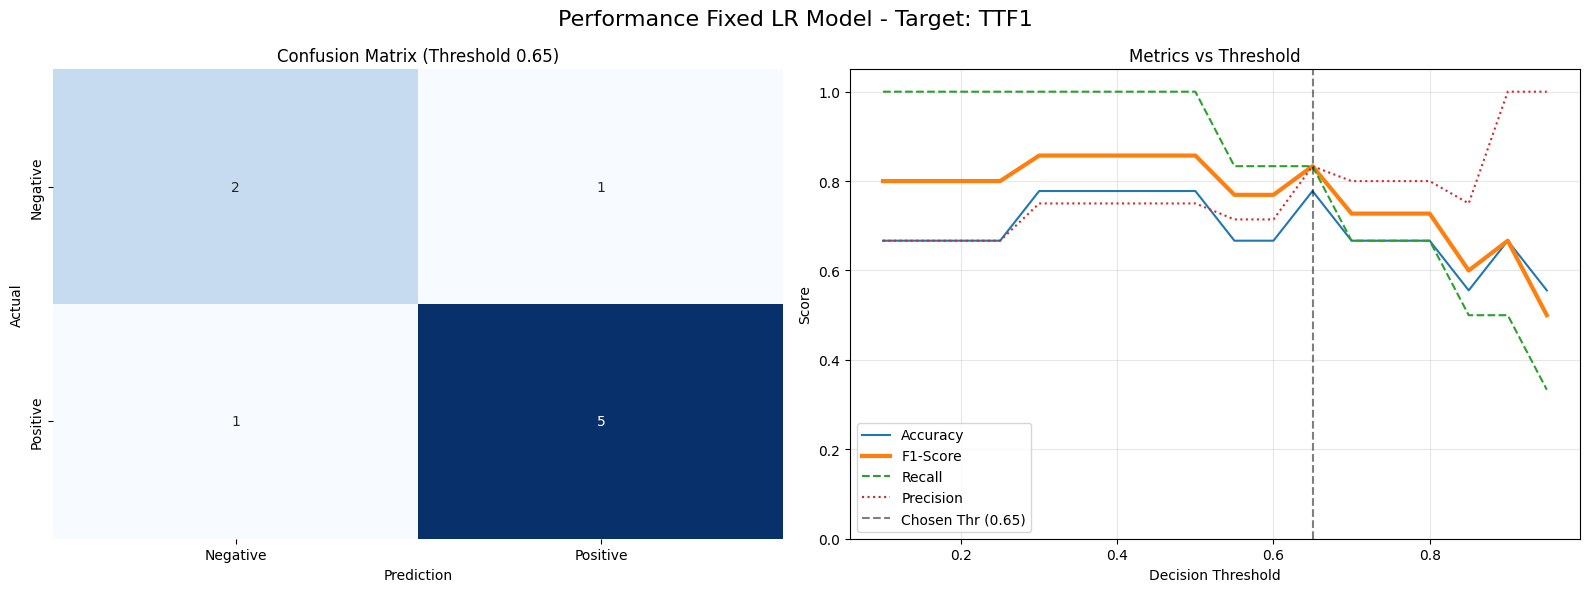

[TTF1 @ 0.65] Acc: 0.7778 | F1: 0.8333 | Recall: 0.8333 | Prec: 0.8333


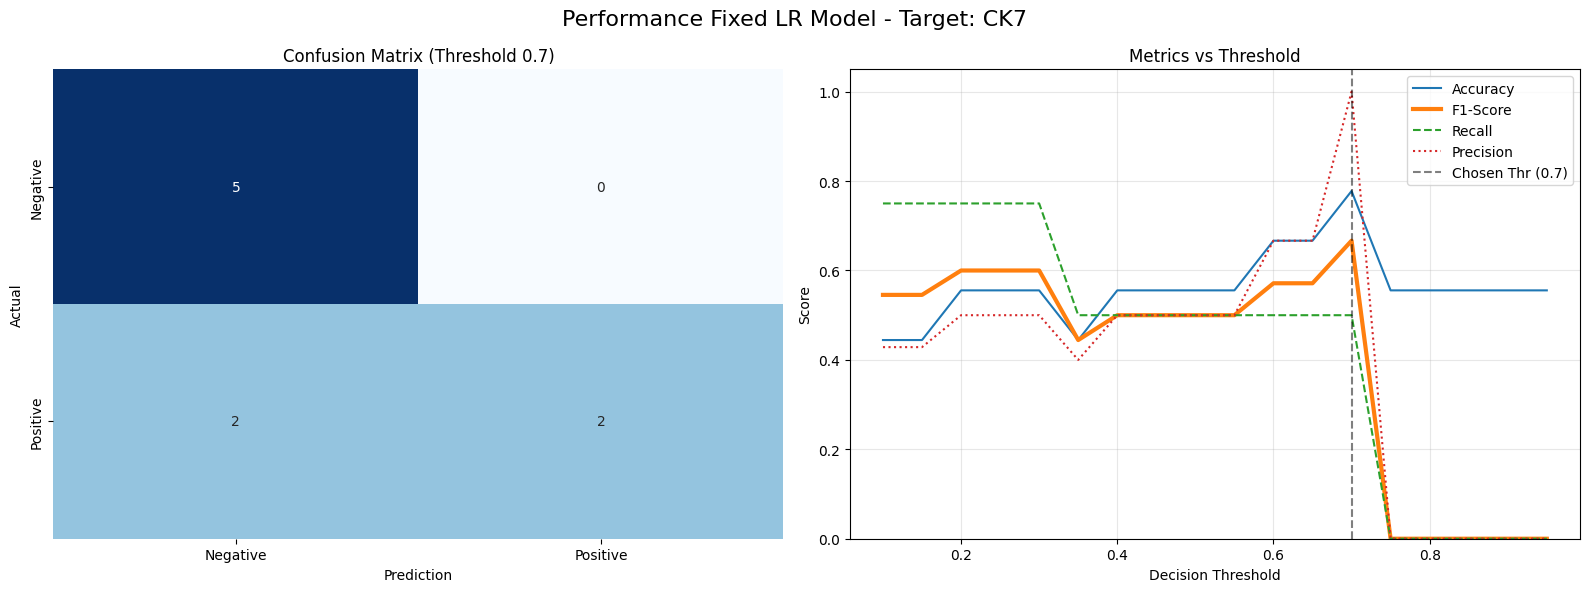

[CK7 @ 0.7] Acc: 0.7778 | F1: 0.6667 | Recall: 0.5000 | Prec: 1.0000


In [ ]:
evaluate_model_performance(model_fixed, test_paths, test_radio, test_labels, model_name="Fixed LR Model", threshold_ttf1=0.65, threshold_ck7=0.7)


Loading base model from: /content/drive/MyDrive/Colab Notebooks/cnn_2d/model_2d_efficientnet_radiomics_finetuned.keras
Backbone Unfrozen
Backbone Unfrozen
Training with SCHEDULER (CosineDecay)
Best model will be saved to: /content/drive/MyDrive/Colab Notebooks/cnn_2d/model_2d_efficientnet_v3_COSINE.keras
Epoch 1/15
    989/Unknown 54s 33ms/step - CK7_acc: 0.6974 - CK7_auc: 0.7598 - CK7_loss: 0.6167 - TTF1_acc: 0.7732 - TTF1_auc: 0.8162 - TTF1_loss: 0.4986 - loss: 2.1647

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_loss improved from inf to 2.65149, saving model to /content/drive/MyDrive/Colab Notebooks/cnn_2d/model_2d_efficientnet_v3_COSINE.keras
990/990 ━━━━━━━━━━━━━━━━━━━━ 60s 39ms/step - CK7_acc: 0.6974 - CK7_auc: 0.7598 - CK7_loss: 0.6167 - TTF1_acc: 0.7732 - TTF1_auc: 0.8162 - TTF1_loss: 0.4986 - loss: 2.1646 - val_CK7_acc: 0.5750 - val_CK7_auc: 0.5912 - val_CK7_loss: 0.8944 - val_TTF1_acc: 0.6205 - val_TTF1_auc: 0.5614 - val_TTF1_loss: 0.7526 - val_loss: 2.6515
Epoch 2/15
989/990 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - CK7_acc: 0.6999 - CK7_auc: 0.7796 - CK7_loss: 0.5846 - TTF1_acc: 0.7896 - TTF1_auc: 0.8270 - TTF1_loss: 0.4786 - loss: 2.0366
Epoch 2: val_loss improved from 2.65149 to 2.59977, saving model to /content/drive/MyDrive/Colab Notebooks/cnn_2d/model_2d_efficientnet_v3_COSINE.keras
990/990 ━━━━━━━━━━━━━━━━━━━━ 42s 36ms/step - CK7_acc: 0.6999 - CK7_auc: 0.7796 - CK7_loss: 0.5847 - TTF1_acc: 0.7896 - TTF1_auc: 0.8270 - TTF1_loss: 0.4785 - loss: 2.0365 - val_CK7_acc: 0.554

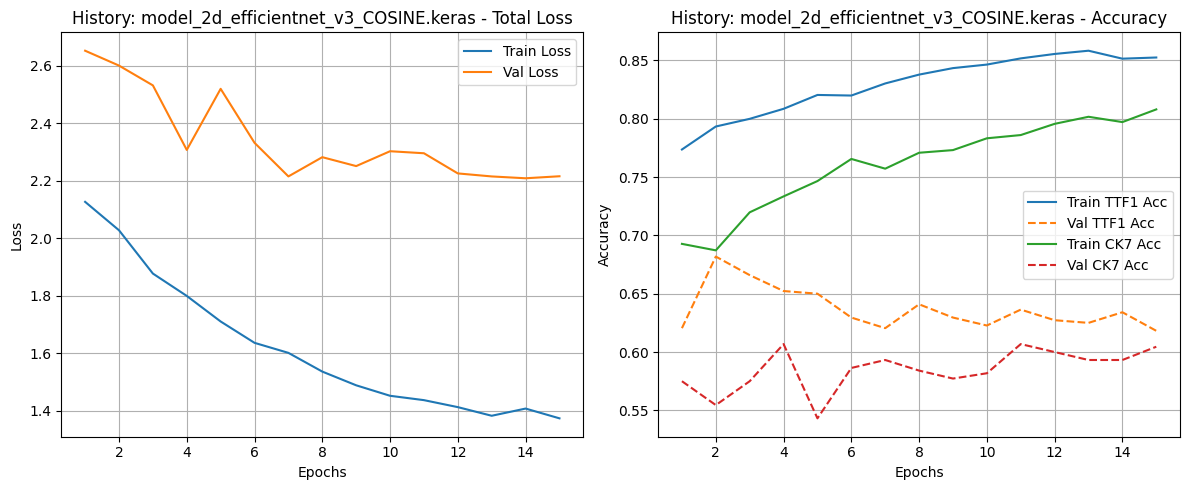

In [ ]:
MODEL_COSINE_PATH = str(BASE_DIR / "cnn_2d/model_2d_efficientnet_v3_COSINE.keras")

decay_steps = 990 * 15

cosine_decay = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-4,
    decay_steps=decay_steps,
    alpha=0.01
)

model_cosine, hist_cosine = run_training_round(
    start_model_path=SAVED_MODEL_PATH,
    train_ds=train_ds,
    val_ds=val_ds,
    epochs=15,
    learning_rate=cosine_decay,
    save_path=MODEL_COSINE_PATH
)


 Starting Evaluation for: Fixed LR Model...
 Thresholds: TTF1=0.7, CK7=0.5
   Processing 9 patients...


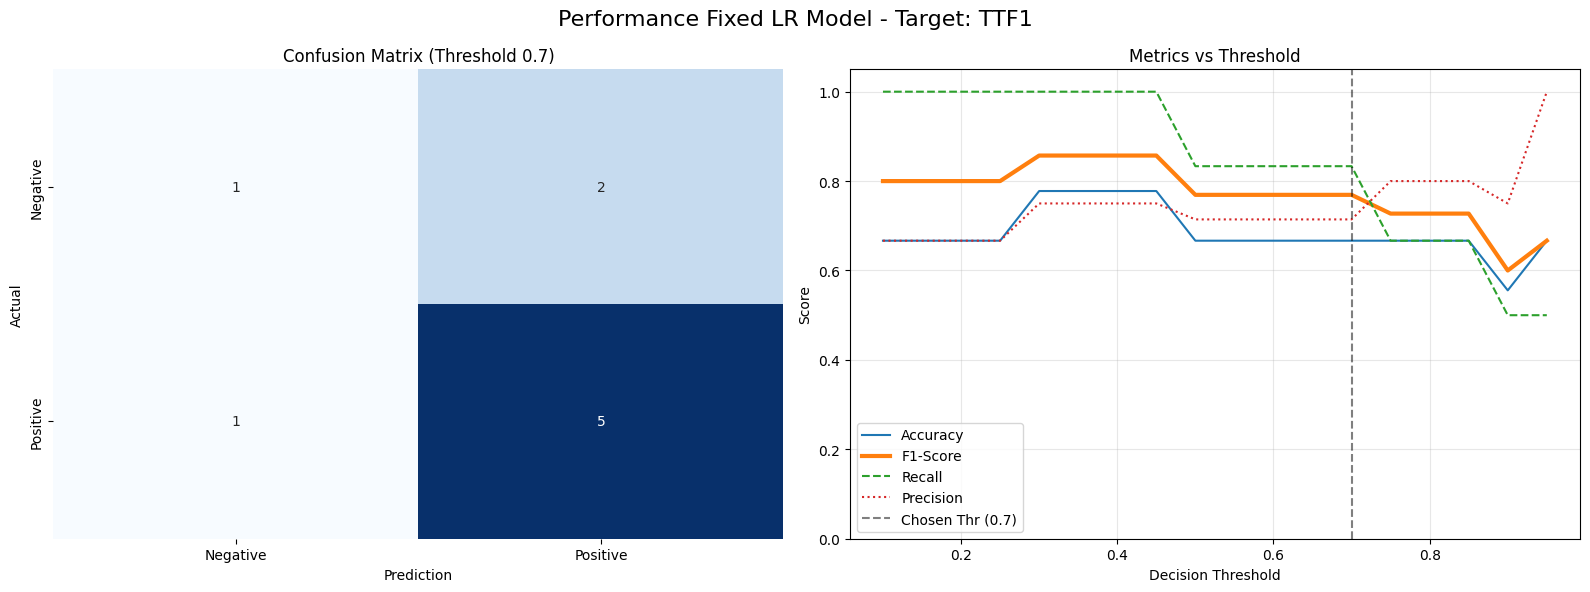

[TTF1 @ 0.7] Acc: 0.6667 | F1: 0.7692 | Recall: 0.8333 | Prec: 0.7143


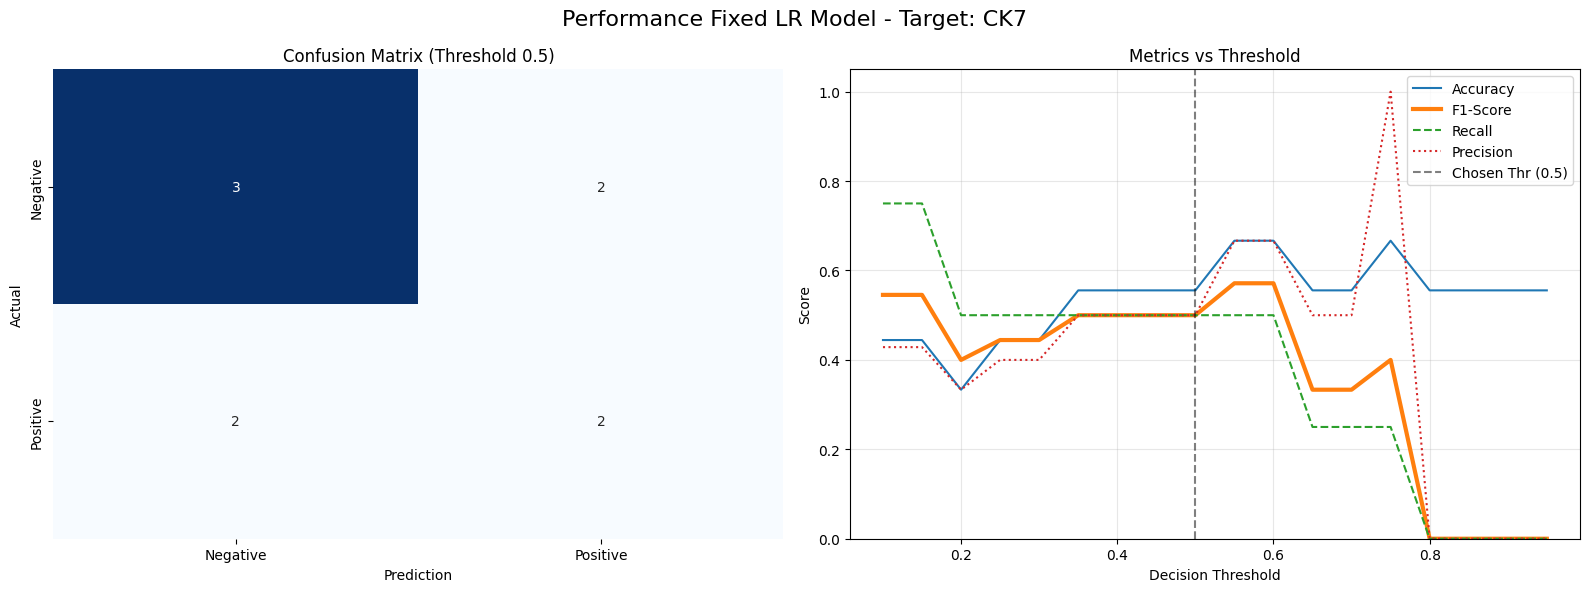

[CK7 @ 0.5] Acc: 0.5556 | F1: 0.5000 | Recall: 0.5000 | Prec: 0.5000


In [ ]:
evaluate_model_performance(model_cosine, test_paths, test_radio, test_labels, model_name="Fixed LR Model", threshold_ttf1=0.7, threshold_ck7=0.5)

In [ ]:
from sklearn.metrics import roc_auc_score
import numpy as np

def calculate_test_auc(model, test_paths, test_radio, test_labels):

    y_true_ttf1, y_prob_ttf1 = [], []
    y_true_ck7, y_prob_ck7 = [], []

    for i in range(len(test_paths)):
        t_ttf1 = test_labels[i][0]
        t_ck7 = test_labels[i][1]

        p_ttf1, p_ck7 = predict_patient_aggregated(model, test_paths[i], test_radio[i])

        y_true_ttf1.append(t_ttf1)
        y_prob_ttf1.append(p_ttf1)
        y_true_ck7.append(t_ck7)
        y_prob_ck7.append(p_ck7)

    auc_ttf1 = roc_auc_score(y_true_ttf1, y_prob_ttf1)
    auc_ck7 = roc_auc_score(y_true_ck7, y_prob_ck7)

    print(f"\n AUC:")
    print(f"   TTF1 AUC: {auc_ttf1:.4f}")
    print(f"   CK7  AUC: {auc_ck7:.4f}")

    return auc_ttf1, auc_ck7

auc_ttf1, auc_ck7 = calculate_test_auc(model_fixed, test_paths, test_radio, test_labels)


 AUC:
   TTF1 AUC: 0.7778
   CK7  AUC: 0.6000


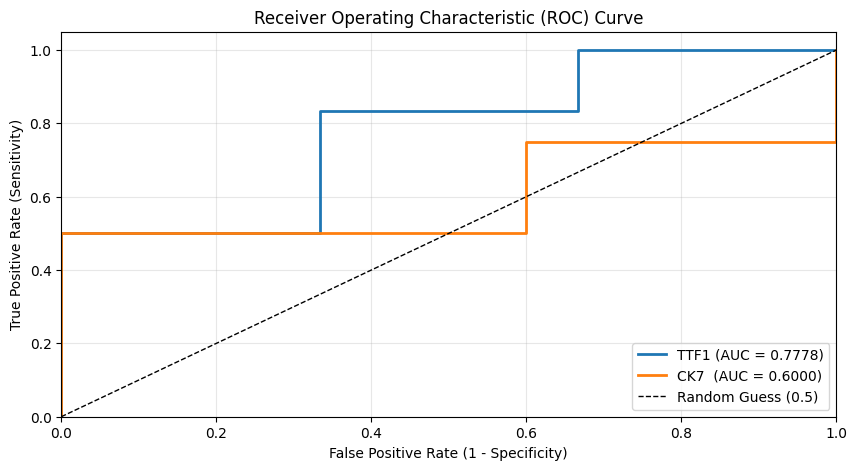

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

def plot_roc_curves(model, test_paths, test_radio, test_labels):

    y_true_ttf1, y_prob_ttf1 = [], []
    y_true_ck7, y_prob_ck7 = [], []

    for i in range(len(test_paths)):
        t_ttf1 = test_labels[i][0]
        t_ck7 = test_labels[i][1]
        p_ttf1, p_ck7 = predict_patient_aggregated(model, test_paths[i], test_radio[i])

        y_true_ttf1.append(t_ttf1)
        y_prob_ttf1.append(p_ttf1)
        y_true_ck7.append(t_ck7)
        y_prob_ck7.append(p_ck7)

    plt.figure(figsize=(10, 5))

    fpr, tpr, _ = roc_curve(y_true_ttf1, y_prob_ttf1)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'TTF1 (AUC = {roc_auc:.4f})', linewidth=2)

    fpr, tpr, _ = roc_curve(y_true_ck7, y_prob_ck7)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'CK7  (AUC = {roc_auc:.4f})', linewidth=2)

    plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random Guess (0.5)')

    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate (1 - Specificity)')
    plt.ylabel('True Positive Rate (Sensitivity)')
    plt.title('Receiver Operating Characteristic (ROC) Curve')
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.show()

plot_roc_curves(model_fixed, test_paths, test_radio, test_labels)